In [1]:
# Step 1: Import required libraries
# Why: Pandas is required for data manipulation and loading the CSV file.
import pandas as pd
import numpy as np

In [2]:
# Step 2: Load the dataset
# Why: To bring the raw customer data into our environment for analysis.
file_path = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(file_path)

In [3]:
# Step 3: Perform initial data inspection
# Why: To understand the dataset's structure, data types, and check for any obvious anomalies before cleaning.
print("--- Dataset Dimensions ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("\n--- Data Types & Non-Null Counts ---")
# Using info() to check column types and spot any immediate missing values
df.info()

print("\n--- First 5 Records ---")
display(df.head())

--- Dataset Dimensions ---
Rows: 7043, Columns: 21

--- Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract   

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Step 4: Data Type Correction & Target Encoding
# Why: TotalCharges is currently an object (string) due to blank spaces, which will break numerical analysis.
# Why: Churn is a categorical variable (Yes/No) that must be encoded to binary (1/0) so that churn rates can be calculated.

# 4.1 Convert 'TotalCharges' to numeric
# errors='coerce' will convert invalid parsing (like blank spaces) to NaN (missing values)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# 4.2 Handle the missing values in 'TotalCharges'
# Why: The missing values are for new customers with 'tenure' = 0. It makes business sense to replace them with 0.
print("Missing TotalCharges before filling:", df['TotalCharges'].isna().sum())
print("Tenure of those customers:", df.loc[df['TotalCharges'].isna(), 'tenure'].unique())
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# 4.3 Encode 'Churn' column
# Why: Converting 'Yes' to 1 and 'No' to 0 lets us calculate the churn rate directly using .mean().
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 4.4 Verify the changes
print("\n--- Data Types After Cleaning ---")
print(df[['TotalCharges', 'Churn']].dtypes)

print("\n--- Check for any remaining missing values ---")
print("Total Missing Values in Dataset:", df.isnull().sum().sum())

Missing TotalCharges before filling: 11
Tenure of those customers: [0]

--- Data Types After Cleaning ---
TotalCharges    float64
Churn             int64
dtype: object

--- Check for any remaining missing values ---
Total Missing Values in Dataset: 0


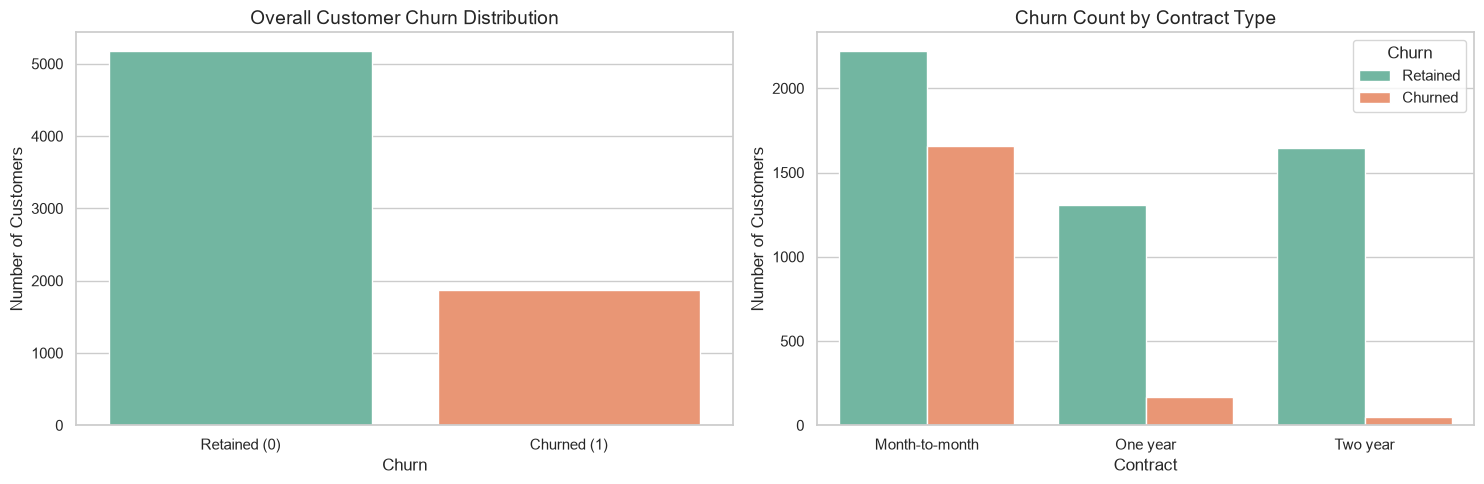

In [5]:
# Step 5: Exploratory Data Analysis (EDA) - Visualizing Churn Drivers
# Why: To visually analyze the overall churn rate and identify which contract type 
# has the highest risk of customers leaving. This helps in forming business retention strategies.

import matplotlib.pyplot as plt
import seaborn as sns

# Set a professional visual style for the charts
sns.set_theme(style="whitegrid")

# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- Plot 1: Overall Churn Distribution ---
# Why: To understand the baseline ratio of retained vs. churned customers.
sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Overall Customer Churn Distribution', fontsize=14)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Retained (0)', 'Churned (1)'])
axes[0].set_ylabel('Number of Customers')

# --- Plot 2: Impact of Contract Type on Churn ---
# Why: To check if the type of contract (Month-to-month, One year, Two year) 
# influences a customer's decision to leave.
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set2', ax=axes[1])
axes[1].set_title('Churn Count by Contract Type', fontsize=14)
axes[1].set_ylabel('Number of Customers')
axes[1].legend(title='Churn', labels=['Retained', 'Churned'])

# Adjust layout for better readability
plt.tight_layout()
plt.show()

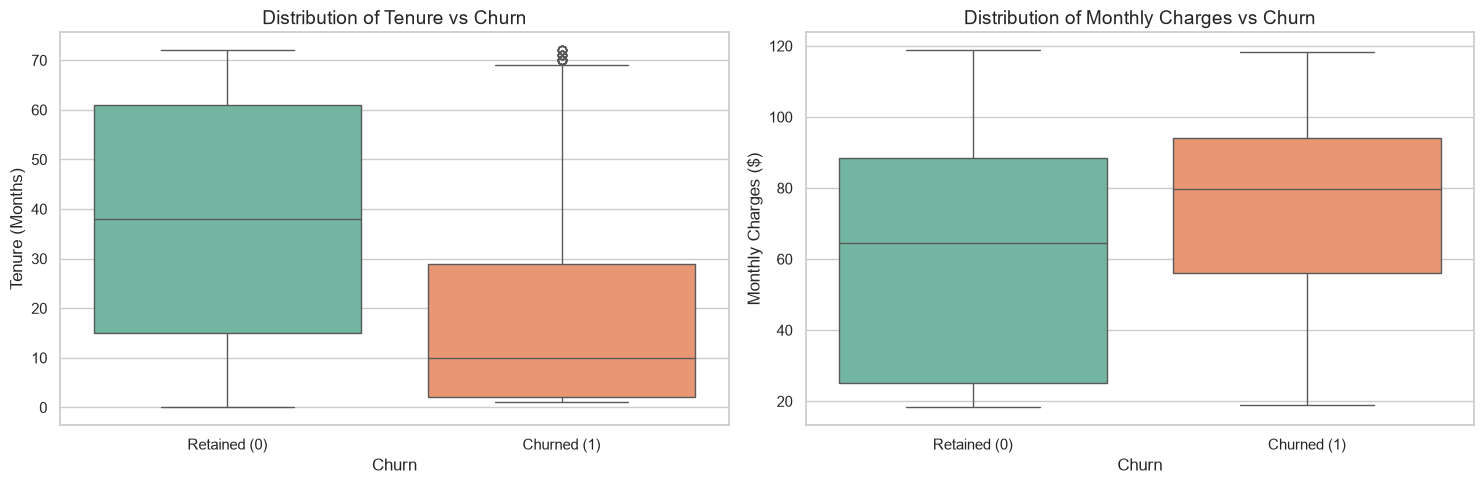

In [6]:
# Step 6: Analyzing Numerical Features (Tenure & Monthly Charges) vs. Churn
# Why: To understand if the length of time a customer stays (tenure) or 
# how much they are paying monthly influences their decision to churn.

# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- Plot 1: Tenure vs Churn ---
# Why: To see if new customers churn more compared to long-term customers.
sns.boxplot(data=df, x='Churn', y='tenure', hue='Churn', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Distribution of Tenure vs Churn', fontsize=14)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Retained (0)', 'Churned (1)'])
axes[0].set_ylabel('Tenure (Months)')

# --- Plot 2: Monthly Charges vs Churn ---
# Why: To analyze if higher monthly bills are driving customers away.
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Distribution of Monthly Charges vs Churn', fontsize=14)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Retained (0)', 'Churned (1)'])
axes[1].set_ylabel('Monthly Charges ($)')

# Adjust layout for better readability
plt.tight_layout()
plt.show()

In [7]:
# Step 7: Drop customerID
# Why: It is just a unique label and has no analytical value.
df = df.drop('customerID', axis=1)

In [8]:
# Step 8: Overall churn rate (baseline)
# Why: To compare every segment's churn against the company average.
print("Overall Churn Rate:", round(df['Churn'].mean() * 100, 2), "%")

Overall Churn Rate: 26.54 %


In [9]:
# Step 9: Identifying Root Causes using Descriptive Analytics (GroupBy)
# Why: As Data Analysts, we use statistical grouping and percentages to explain 
# the business problem, rather than complex Machine Learning models.

print("--- Churn Rate by Contract Type ---")
# Why: To see which contract type has the highest percentage of customers leaving.
contract_churn = df.groupby('Contract')['Churn'].mean() * 100
print(contract_churn.round(2).astype(str) + '%')

print("\n--- Churn Rate by Internet Service ---")
# Why: To check if a specific service type (like Fiber Optic) is causing customer dissatisfaction.
internet_churn = df.groupby('InternetService')['Churn'].mean() * 100
print(internet_churn.round(2).astype(str) + '%')

print("\n--- Churn Rate by Tenure (Customer Lifetime in Months) ---")
# Why: To identify at what stage of their lifecycle customers leave the most.
# Grouping customers into 'New', 'Mid-term', and 'Loyal' to make business sense.
df['Tenure_Group'] = pd.cut(df['tenure'], bins=[-1, 12, 36, 100], labels=['New (0-12m)', 'Mid (13-36m)', 'Loyal (>36m)'])
tenure_churn = df.groupby('Tenure_Group', observed=False)['Churn'].mean() * 100
print(tenure_churn.round(2).astype(str) + '%')

--- Churn Rate by Contract Type ---
Contract
Month-to-month    42.71%
One year          11.27%
Two year           2.83%
Name: Churn, dtype: str

--- Churn Rate by Internet Service ---
InternetService
DSL            18.96%
Fiber optic    41.89%
No               7.4%
Name: Churn, dtype: str

--- Churn Rate by Tenure (Customer Lifetime in Months) ---
Tenure_Group
New (0-12m)     47.44%
Mid (13-36m)    25.54%
Loyal (>36m)    11.93%
Name: Churn, dtype: str


In [10]:
# Step 10: Impact of add-on services on churn
# Why: To check if customers with Online Security and Tech Support churn less.
# Note: Customers without internet service are excluded, as they cannot have these add-ons.
for col in ['OnlineSecurity', 'TechSupport']:
    print(f"--- Churn Rate by {col} (%) ---")
    print(df[df['InternetService'] != 'No'].groupby(col)['Churn'].mean().mul(100).round(2))
    print()

--- Churn Rate by OnlineSecurity (%) ---
OnlineSecurity
No     41.77
Yes    14.61
Name: Churn, dtype: float64

--- Churn Rate by TechSupport (%) ---
TechSupport
No     41.64
Yes    15.17
Name: Churn, dtype: float64

